# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv('insurance.csv')

In [3]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
# Periksa missing value.
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(exclude='number'):
    print(df[col].value_counts(), '\n')

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


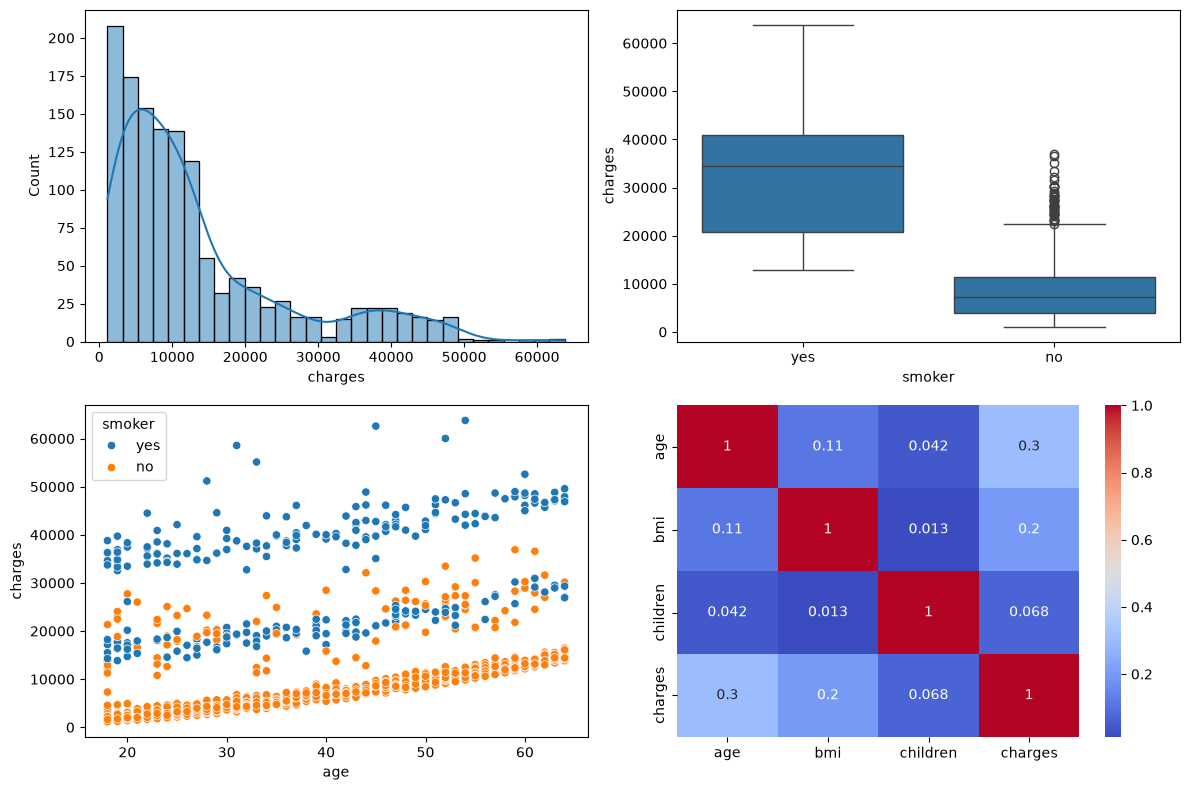

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['charges'], kde=True, ax=ax[0, 0])
sns.boxplot(x='smoker', y='charges', data=df, ax=ax[0, 1])
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=ax[1, 0])
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm', ax=ax[1, 1])
plt.tight_layout()
plt.show()

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [9]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns='charges')
y = df['charges']

In [10]:
# Identifikasi kolom numerik dan kategorikal.
num_cols = X.select_dtypes('number').columns
cat_cols = X.select_dtypes(exclude='number').columns

In [11]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
prep_scaled = ColumnTransformer([('num', StandardScaler(), num_cols),
                                 ('cat', OneHotEncoder(drop='first'), cat_cols)])
prep_tree = ColumnTransformer([('num', 'passthrough', num_cols),
                               ('cat', OneHotEncoder(drop='first'), cat_cols)])

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [13]:
# Inisialisasi dan latih Linear Regression.
lr = make_pipeline(prep_scaled, LinearRegression()).fit(X_train, y_train)

In [14]:
# Lakukan prediksi pada test set.
y_pred_lr = lr.predict(X_test)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [15]:
# Buat fitur polynomial dan latih model.
poly = GridSearchCV(make_pipeline(prep_scaled, PolynomialFeatures(), LinearRegression()),
                    {'polynomialfeatures__degree': [1, 2, 3, 4]}, cv=5).fit(X_train, y_train)
poly.best_params_

{'polynomialfeatures__degree': 2}

In [16]:
# Lakukan prediksi pada test set.
y_pred_poly = poly.predict(X_test)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [17]:
# Inisialisasi dan latih Ridge Regression.
ridge = GridSearchCV(make_pipeline(prep_scaled, Ridge()),
                     {'ridge__alpha': [0.01, 0.1, 1, 10, 100]}, cv=5).fit(X_train, y_train)
ridge.best_params_

{'ridge__alpha': 1}

In [18]:
# Lakukan prediksi pada test set.
y_pred_ridge = ridge.predict(X_test)

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [19]:
# Inisialisasi dan latih Lasso Regression.
lasso = GridSearchCV(make_pipeline(prep_scaled, Lasso()),
                     {'lasso__alpha': [1, 10, 100, 1000]}, cv=5).fit(X_train, y_train)
lasso.best_params_

{'lasso__alpha': 100}

In [20]:
# Lakukan prediksi pada test set.
y_pred_lasso = lasso.predict(X_test)

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [21]:
# Inisialisasi dan latih Decision Tree Regressor.
dt = GridSearchCV(make_pipeline(prep_tree, DecisionTreeRegressor(random_state=42)),
                  {'decisiontreeregressor__max_depth': [3, 4, 5, 6, 8],
                   'decisiontreeregressor__min_samples_leaf': [1, 5, 10, 20]}, cv=5).fit(X_train, y_train)
dt.best_params_

{'decisiontreeregressor__max_depth': 4,
 'decisiontreeregressor__min_samples_leaf': 1}

In [22]:
# Lakukan prediksi pada test set.
y_pred_dt = dt.predict(X_test)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [23]:
# Inisialisasi dan latih SVR.
svr = GridSearchCV(make_pipeline(prep_scaled, SVR()),
                   {'svr__C': [1e3, 1e4, 5e4, 1e5], 'svr__epsilon': [100, 1000]}, cv=5).fit(X_train, y_train)
svr.best_params_

{'svr__C': 50000.0, 'svr__epsilon': 1000}

In [24]:
# Lakukan prediksi pada test set.
y_pred_svr = svr.predict(X_test)

# 4. Evaluasi Model

In [25]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
preds = {'Linear': y_pred_lr, 'Polynomial': y_pred_poly, 'Ridge': y_pred_ridge,
         'Lasso': y_pred_lasso, 'Decision Tree': y_pred_dt, 'SVR': y_pred_svr}
hasil = pd.DataFrame({n: {'MAE': mean_absolute_error(y_test, p),
                          'MSE': mean_squared_error(y_test, p),
                          'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                          'R2': r2_score(y_test, p)} for n, p in preds.items()}).T
hasil

,MAE,MSE,RMSE,R2
Linear,4181.194474,3.359692e+07,5796.284659,0.783593
Polynomial,2729.500134,2.071281e+07,4551.132385,0.866583
Ridge,4193.195353,3.364539e+07,5800.464938,0.783281
Lasso,4248.492453,3.426606e+07,5853.722107,0.779283
Decision Tree,2697.765431,2.109348e+07,4592.764310,0.864131
SVR,2226.229551,2.133367e+07,4618.838308,0.862584


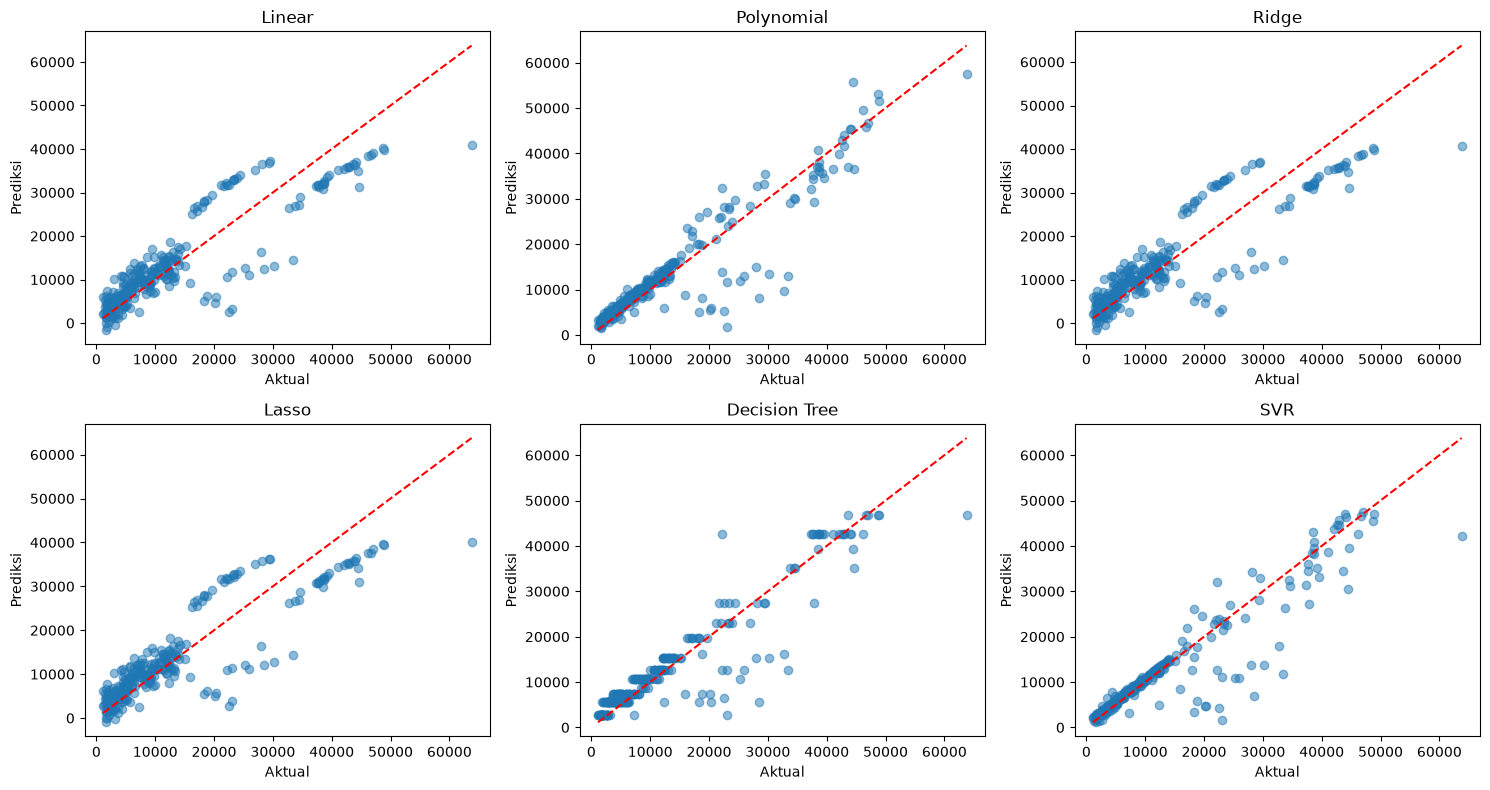

In [26]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (n, p) in zip(axes.flat, preds.items()):
    ax.scatter(y_test, p, alpha=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    ax.set(title=n, xlabel='Aktual', ylabel='Prediksi')
plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


**Perbandingan (test set):**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear | 4181 | 5796 | 0.784 |
| Polynomial (degree=2) | 2730 | 4551 | **0.867** |
| Ridge (alpha=1) | 4193 | 5800 | 0.783 |
| Lasso (alpha=100) | 4248 | 5854 | 0.779 |
| Decision Tree (max_depth=4, min_samples_leaf=1) | 2698 | 4593 | 0.864 |
| SVR (C=50000, epsilon=1000) | **2226** | 4619 | 0.863 |

- **Linear, Ridge, Lasso** hasilnya hampir sama (R² ≈ 0.78). Data tidak overfit sehingga regularisasi tidak banyak berpengaruh; alpha terbaik kecil (Ridge) atau hanya sedikit mengecilkan koefisien (Lasso).
- **Polynomial degree 2** naik signifikan (R² 0.867, RMSE terkecil) karena dapat menangkap interaksi seperti `smoker × bmi` dan `smoker × age` yang terlihat di EDA. Degree lebih tinggi justru turun di cross-validation (overfit).
- **Decision Tree** dengan `max_depth=4` mampu memecah data berdasarkan `smoker`, `bmi`, dan `age` secara non-linear. Depth dibatasi agar tidak overfit.
- **SVR** memiliki MAE terkecil, tetapi wajib di-scaling dan butuh `C` besar karena skala target `charges` besar (puluhan ribu).
- **Preprocessing:** OneHotEncoder mengubah `sex`, `smoker`, `region` menjadi numerik. StandardScaler penting untuk model berbasis jarak/regularisasi (Ridge, Lasso, SVR); Decision Tree tidak terpengaruh scaling sehingga memakai fitur asli. Semua parameter dipilih dengan GridSearchCV (5-fold) pada train set.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.


**Kesimpulan:**
- Fitur paling berpengaruh terhadap `charges` adalah `smoker`, lalu `age` dan `bmi`.
- Model non-linear (Polynomial degree 2, Decision Tree, SVR) lebih baik dari model linear (R² ≈ 0.86 vs 0.78).
- Polynomial Regression degree 2 terbaik secara R² dan RMSE, SVR terbaik secara MAE.
- Ridge dan Lasso tidak memberi peningkatan berarti dibanding Linear Regression.

**Saran:**
- Transformasi target dengan `log(charges)` karena distribusinya right-skewed.
- Tambah fitur interaksi manual, misal `smoker × bmi` atau kategori `bmi > 30` (obesitas).
- Coba model ensemble seperti Random Forest atau Gradient Boosting.
- Perluas grid parameter (misal `gamma` pada SVR) dan gunakan cross-validation untuk evaluasi akhir.